Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Ennio_Doorbell', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'Samsung_SNH_1011_N_Webcam', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: Danmini_Doorbell
Dataset is merged and labeled. Total rows: 10000


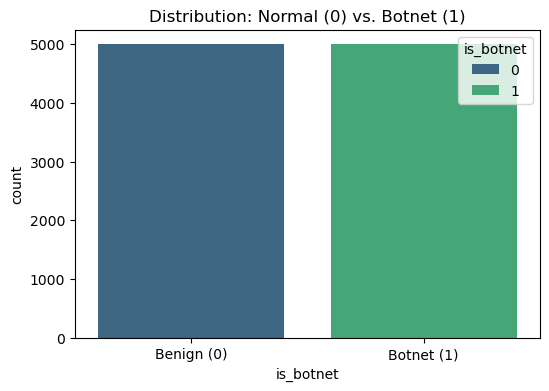

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4494
           1       1.00      1.00      1.00      4506

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9990


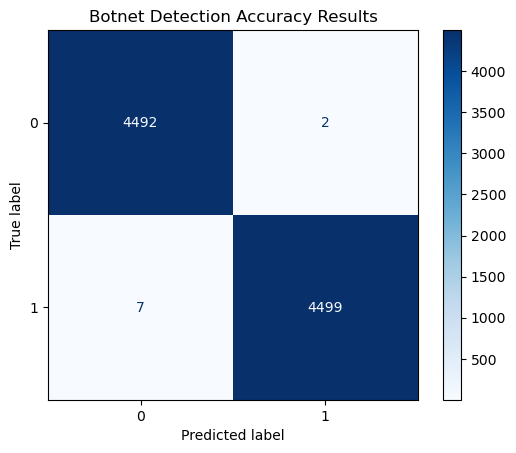

Model saved successfully as 'botnet_detector.pkl'
STATUS: Network Traffic is Normal.


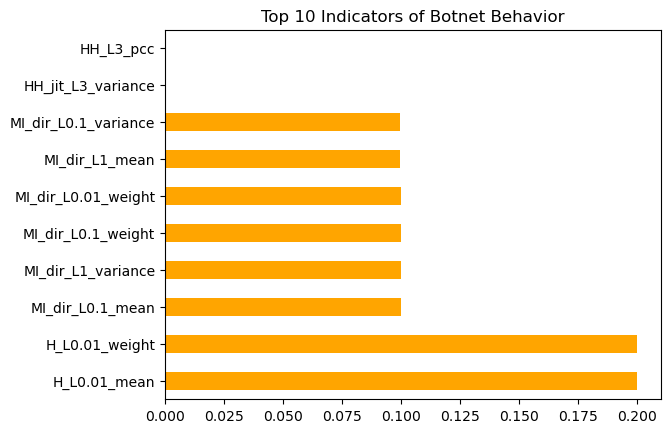

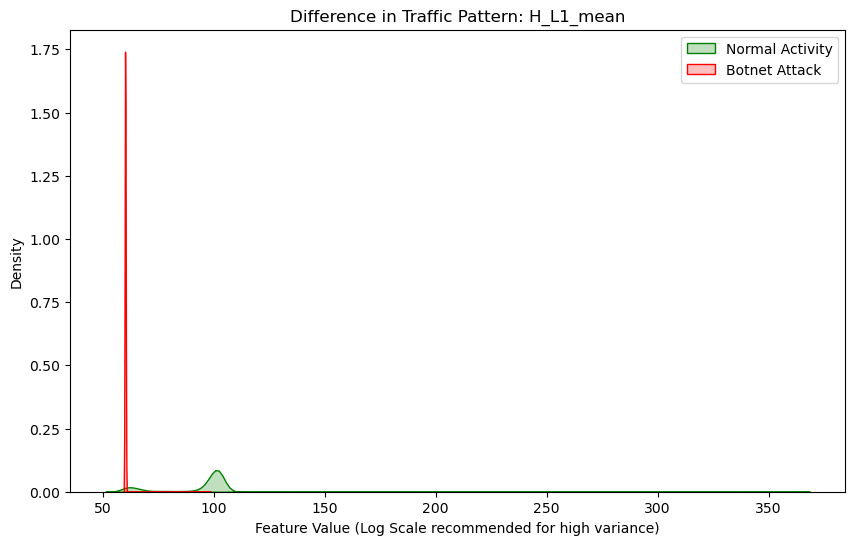

--- Testing 5 Random Samples ---
Sample 1: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 2: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 3: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 4: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 5: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS


In [1]:
# Danmini_Doorbell
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data2'))
device_name = 'Danmini_Doorbell'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data2/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data2/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Ennio_Doorbell', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'Samsung_SNH_1011_N_Webcam', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: Ecobee_Thermostat
Dataset is merged and labeled. Total rows: 10000


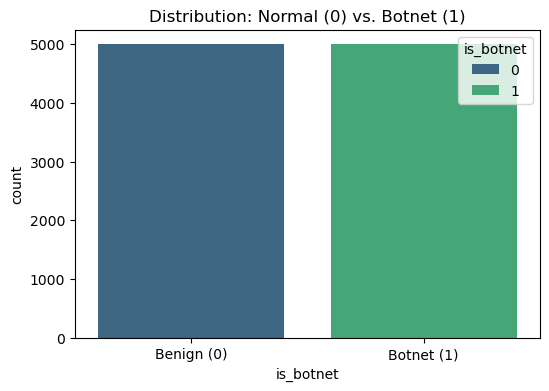

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4488
           1       1.00      1.00      1.00      4512

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9987


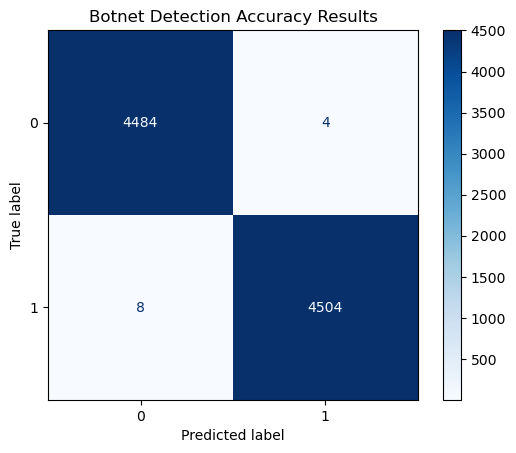

Model saved successfully as 'botnet_detector.pkl'
STATUS: Network Traffic is Normal.


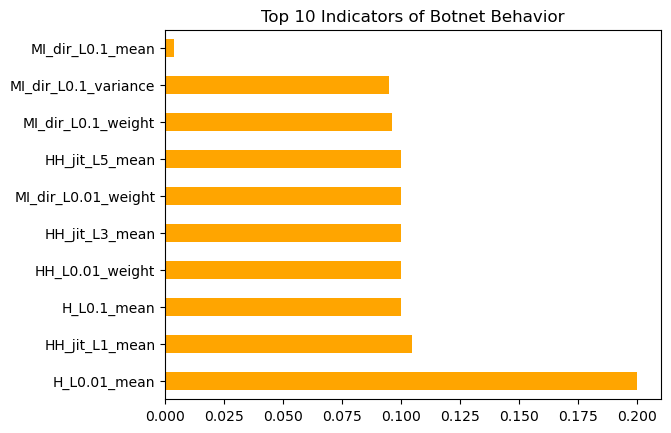

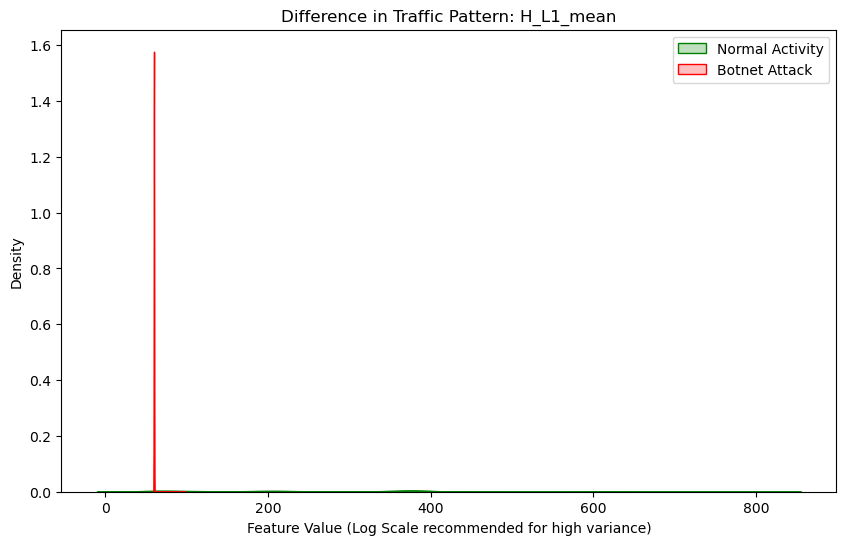

--- Testing 5 Random Samples ---
Sample 1: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 2: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 3: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 4: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 5: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS


In [17]:
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data2'))
device_name = 'Ecobee_Thermostat'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data2/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data2/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Ennio_Doorbell', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'Samsung_SNH_1011_N_Webcam', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: Ennio_Doorbell
Dataset is merged and labeled. Total rows: 10000


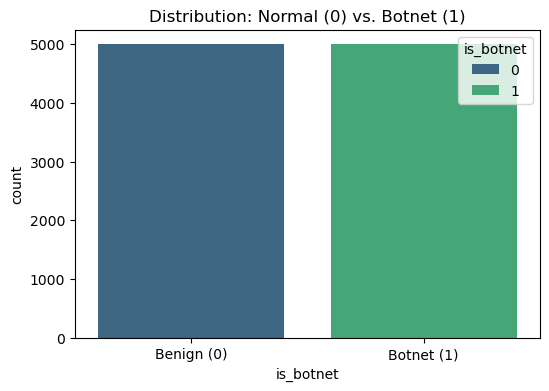

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4514
           1       1.00      1.00      1.00      4486

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9989


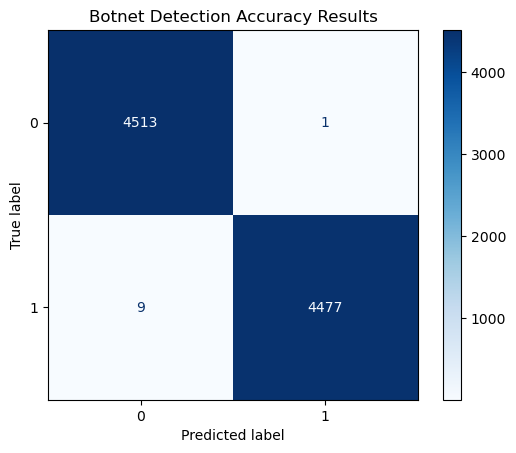

Model saved successfully as 'botnet_detector.pkl'
ALERT: Botnet Activity Detected!


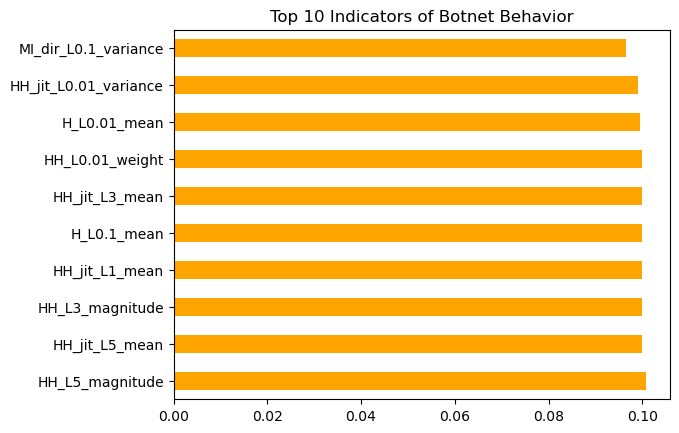

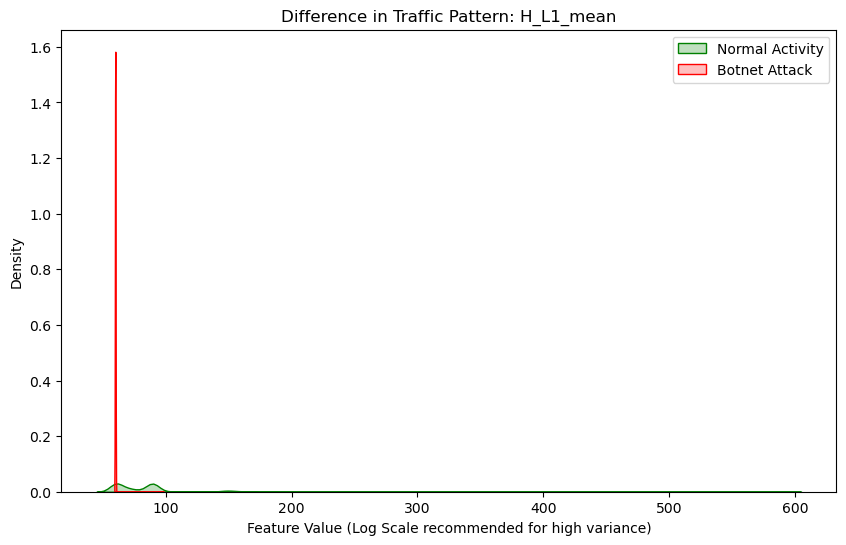

--- Testing 5 Random Samples ---
Sample 1: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 2: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 3: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 4: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 5: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS


In [3]:
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data2'))
device_name = 'Ennio_Doorbell'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data2/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data2/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Ennio_Doorbell', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'Samsung_SNH_1011_N_Webcam', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: Philips_B120N10_Baby_Monitor
Dataset is merged and labeled. Total rows: 10000


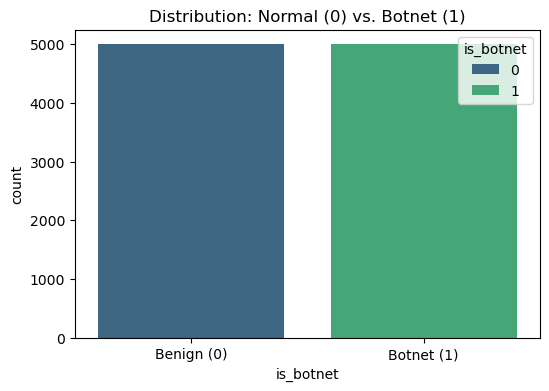

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4514
           1       1.00      1.00      1.00      4486

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9992


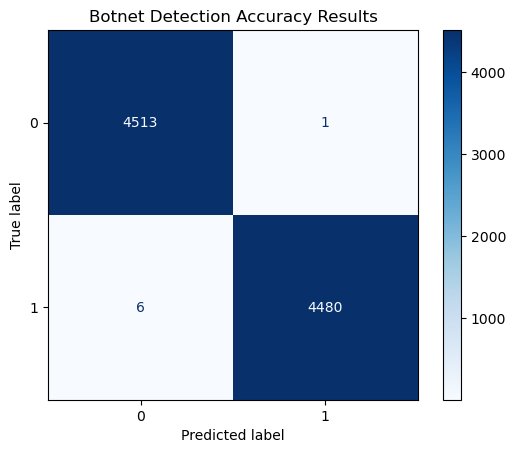

Model saved successfully as 'botnet_detector.pkl'
STATUS: Network Traffic is Normal.


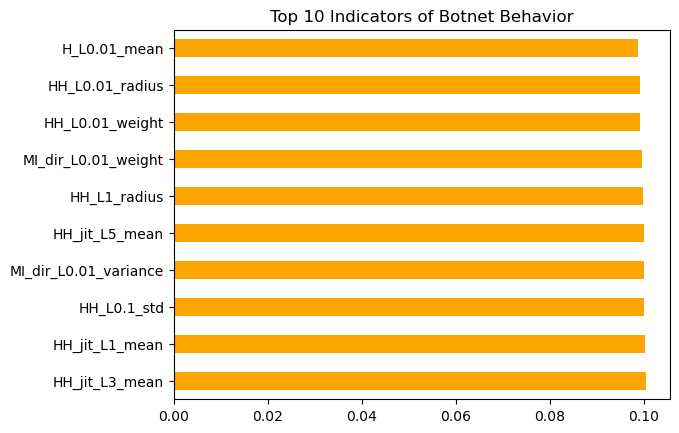

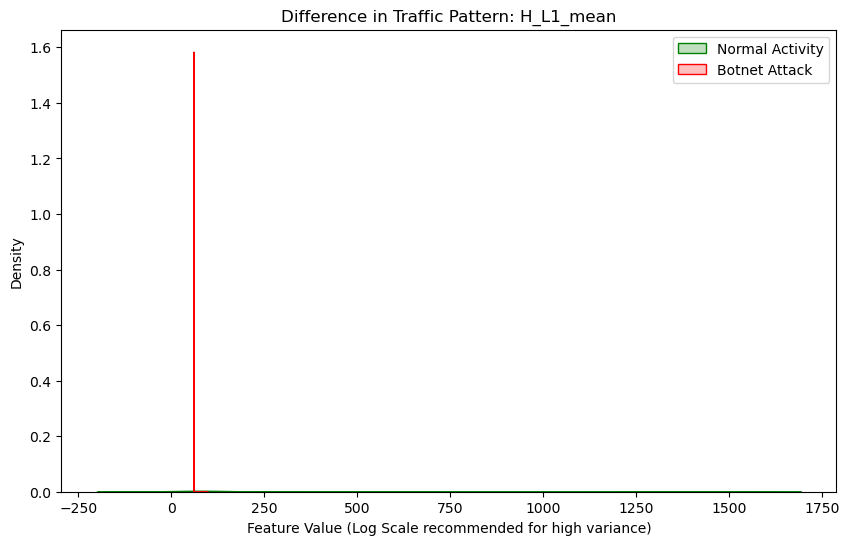

--- Testing 5 Random Samples ---
Sample 1: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 2: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 3: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 4: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 5: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS


In [4]:
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data2'))
device_name = 'Philips_B120N10_Baby_Monitor'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data2/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data2/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Ennio_Doorbell', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'Samsung_SNH_1011_N_Webcam', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: Provision_PT_737E_Security_Camera
Dataset is merged and labeled. Total rows: 10000


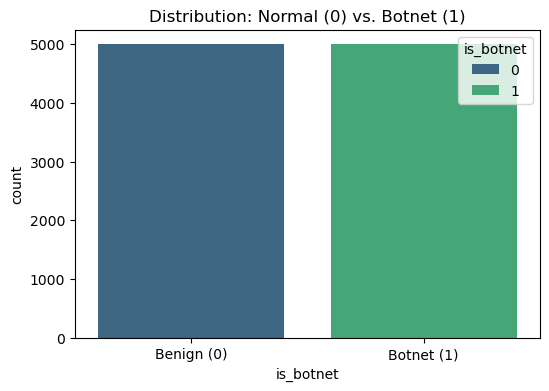

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4495
           1       1.00      1.00      1.00      4505

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9990


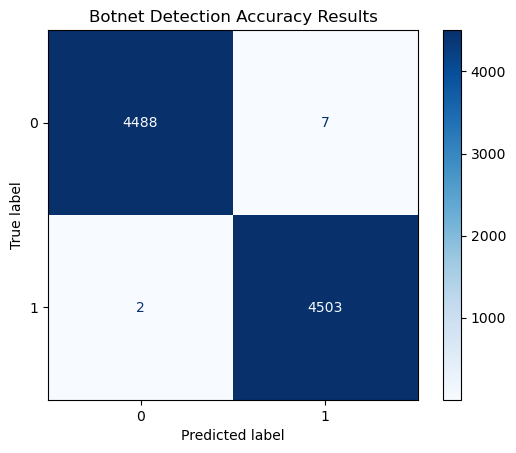

Model saved successfully as 'botnet_detector.pkl'
ALERT: Botnet Activity Detected!


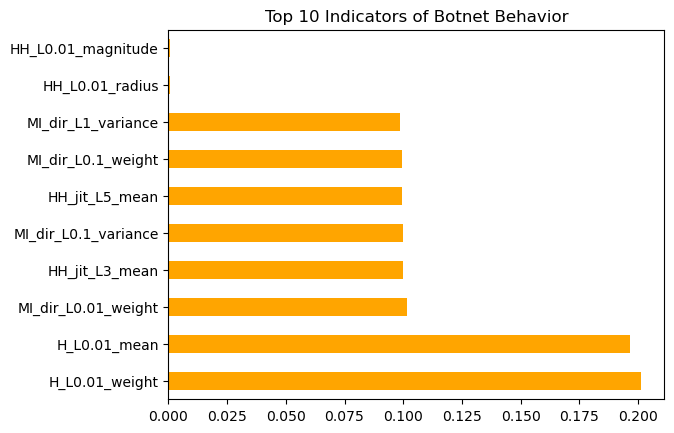

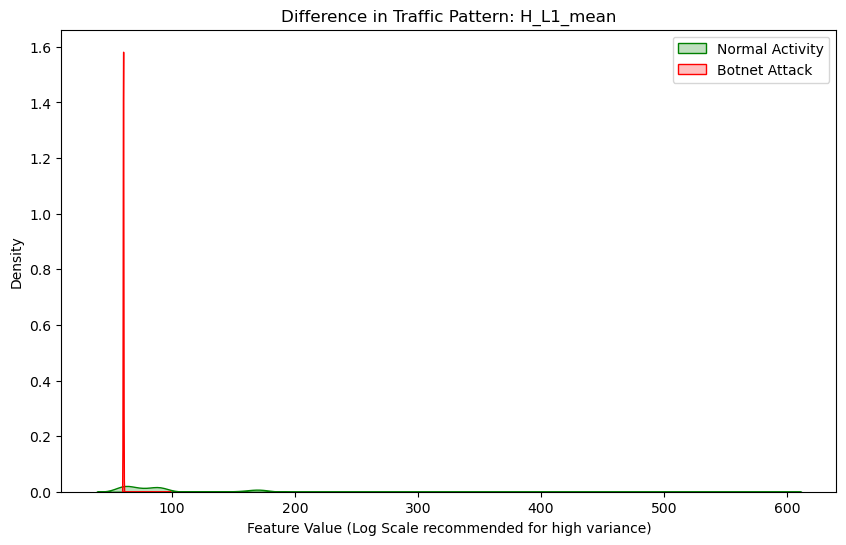

--- Testing 5 Random Samples ---
Sample 1: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 2: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 3: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 4: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 5: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS


In [5]:
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data2'))
device_name = 'Provision_PT_737E_Security_Camera'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data2/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data2/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Ennio_Doorbell', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'Samsung_SNH_1011_N_Webcam', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: Provision_PT_838_Security_Camera
Dataset is merged and labeled. Total rows: 10000


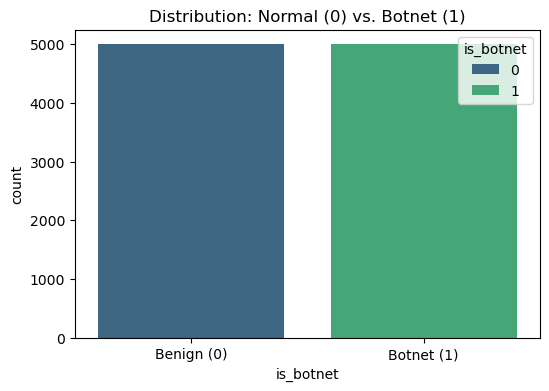

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4497
           1       1.00      1.00      1.00      4503

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9988


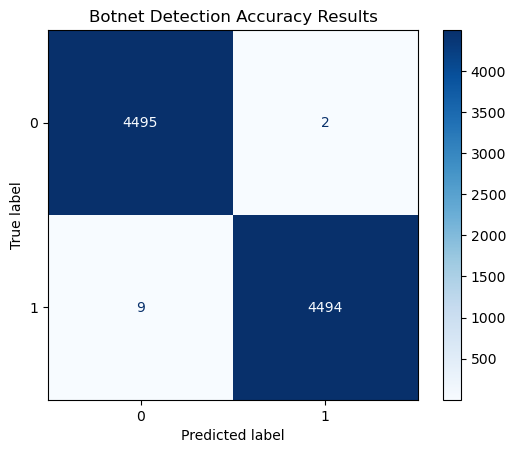

Model saved successfully as 'botnet_detector.pkl'
STATUS: Network Traffic is Normal.


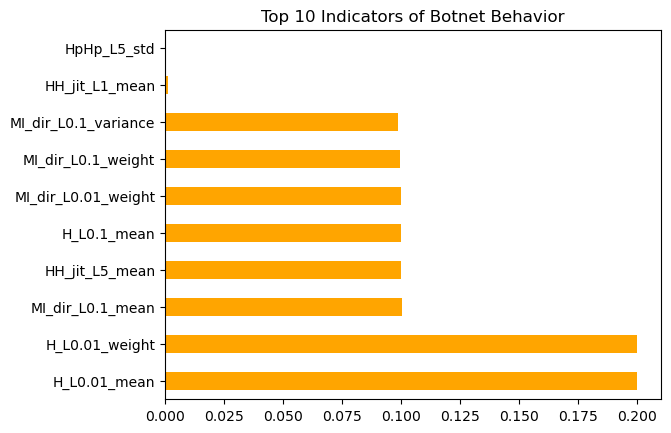

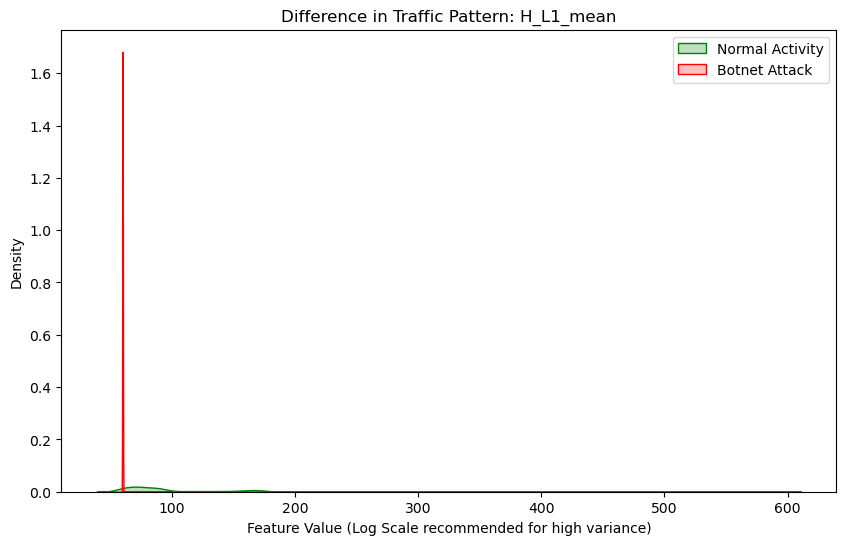

--- Testing 5 Random Samples ---
Sample 1: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 2: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 3: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 4: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 5: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS


In [6]:
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data2'))
device_name = 'Provision_PT_838_Security_Camera'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data2/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data2/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Ennio_Doorbell', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'Samsung_SNH_1011_N_Webcam', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: Samsung_SNH_1011_N_Webcam
Dataset is merged and labeled. Total rows: 10000


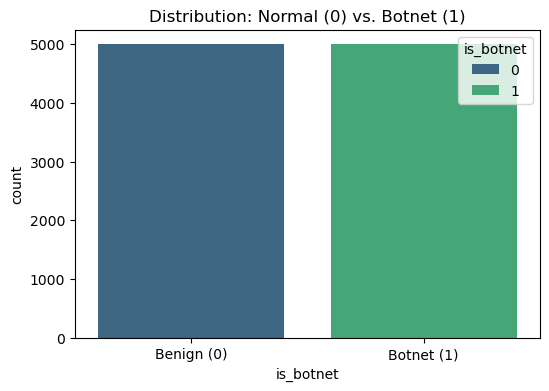

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4502
           1       1.00      1.00      1.00      4498

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9992


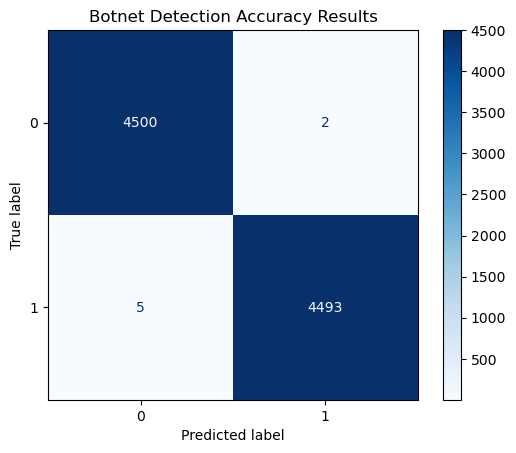

Model saved successfully as 'botnet_detector.pkl'
ALERT: Botnet Activity Detected!


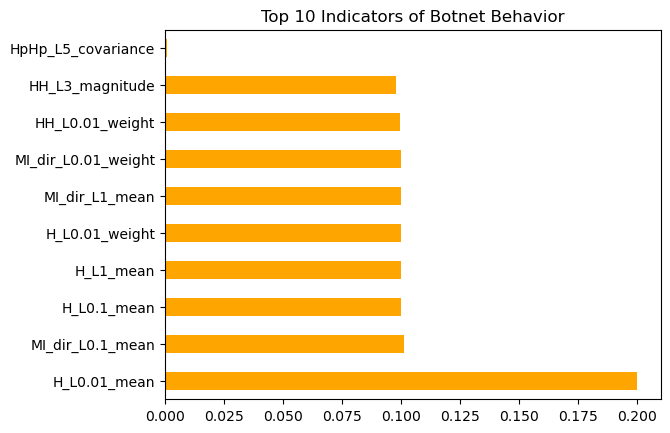

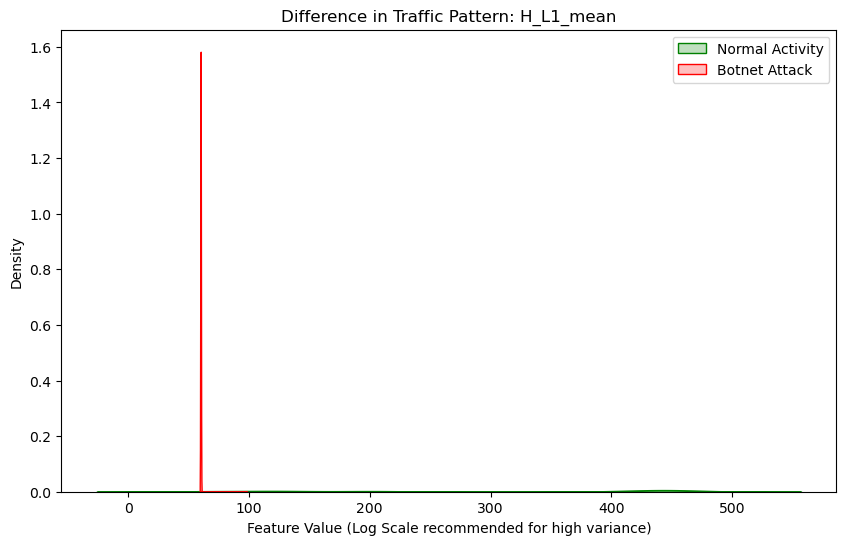

--- Testing 5 Random Samples ---
Sample 1: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 2: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 3: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 4: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 5: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS


In [7]:
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data2'))
device_name = 'Samsung_SNH_1011_N_Webcam'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data2/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data2/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Ennio_Doorbell', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'Samsung_SNH_1011_N_Webcam', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: SimpleHome_XCS7_1002_WHT_Security_Camera
Dataset is merged and labeled. Total rows: 10000


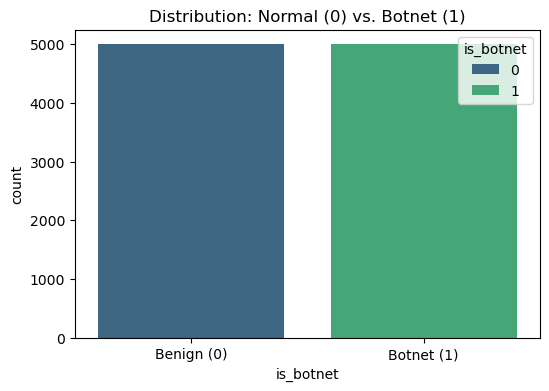

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4516
           1       1.00      1.00      1.00      4484

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9987


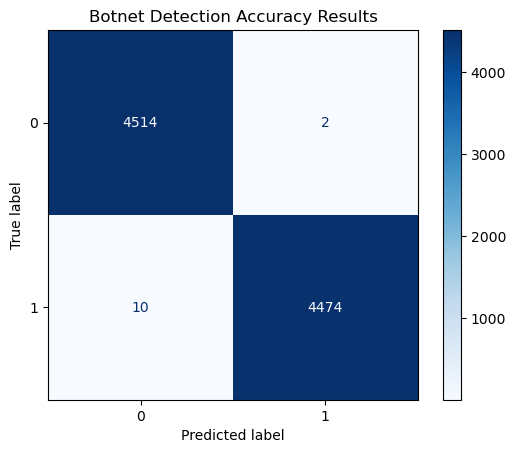

Model saved successfully as 'botnet_detector.pkl'
ALERT: Botnet Activity Detected!


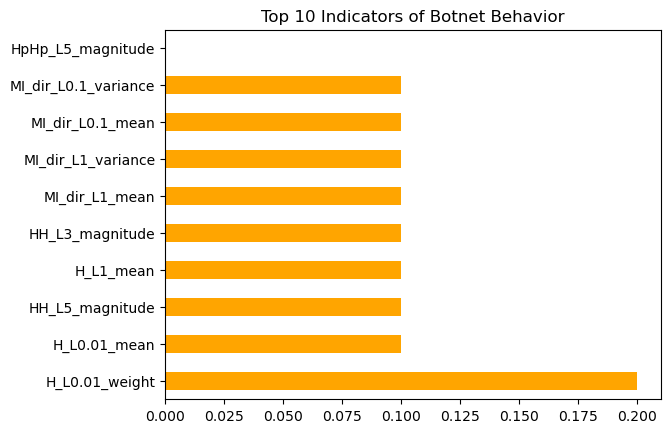

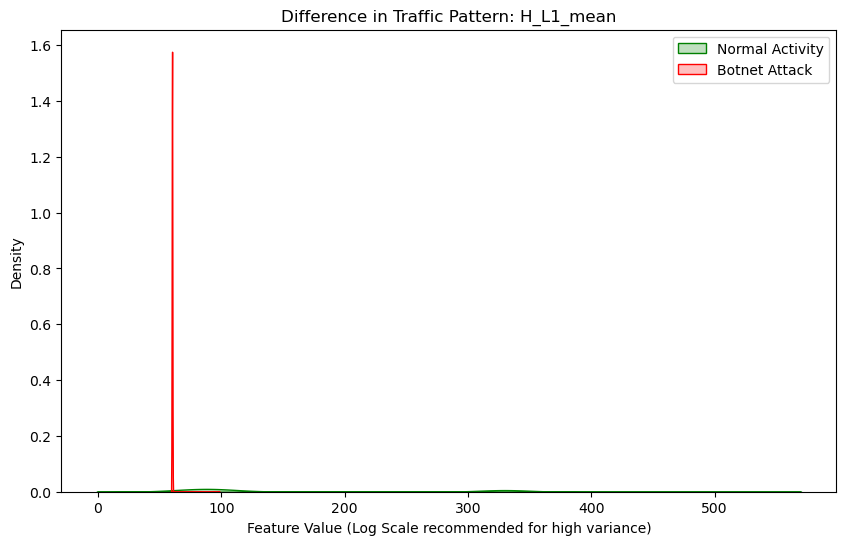

--- Testing 5 Random Samples ---
Sample 1: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 2: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 3: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 4: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 5: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS


In [8]:
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data2'))
device_name = 'SimpleHome_XCS7_1002_WHT_Security_Camera'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data2/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data2/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


Files found in data folder: ['Danmini_Doorbell', 'Ecobee_Thermostat', 'Ennio_Doorbell', 'Philips_B120N10_Baby_Monitor', 'Provision_PT_737E_Security_Camera', 'Provision_PT_838_Security_Camera', 'Samsung_SNH_1011_N_Webcam', 'SimpleHome_XCS7_1002_WHT_Security_Camera', 'SimpleHome_XCS7_1003_WHT_Security_Camera']
Successfully loaded 5000 benign rows and 5000 attack rows.
Now analyzing: SimpleHome_XCS7_1003_WHT_Security_Camera
Dataset is merged and labeled. Total rows: 10000


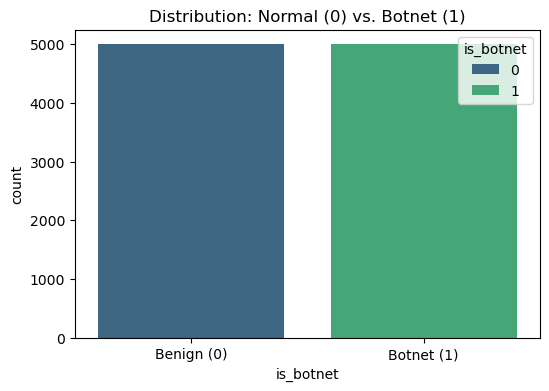

Data split complete.
Training rows: 1000
Testing rows: 9000
AI Model Training Complete!
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4485
           1       1.00      1.00      1.00      4515

    accuracy                           1.00      9000
   macro avg       1.00      1.00      1.00      9000
weighted avg       1.00      1.00      1.00      9000

Accuracy Score: 0.9987


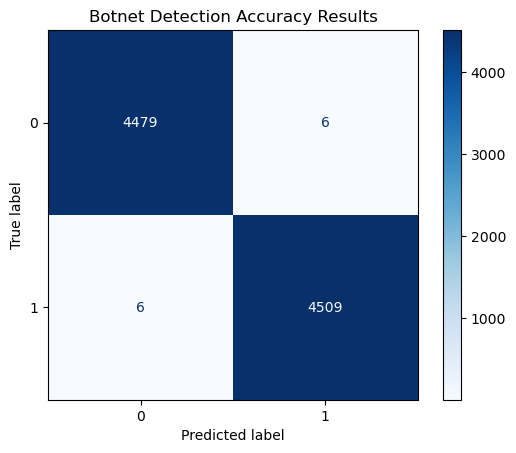

Model saved successfully as 'botnet_detector.pkl'
STATUS: Network Traffic is Normal.


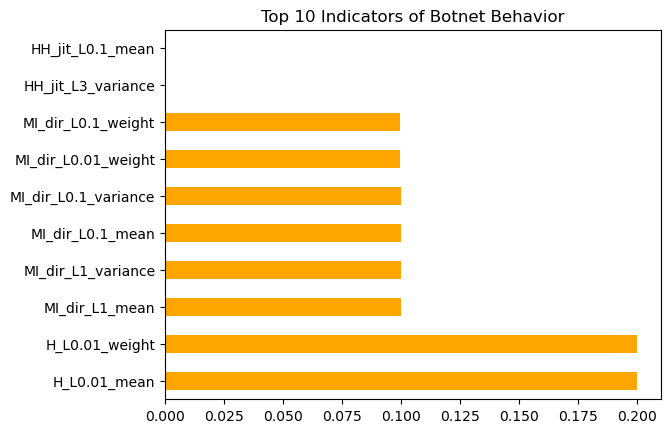

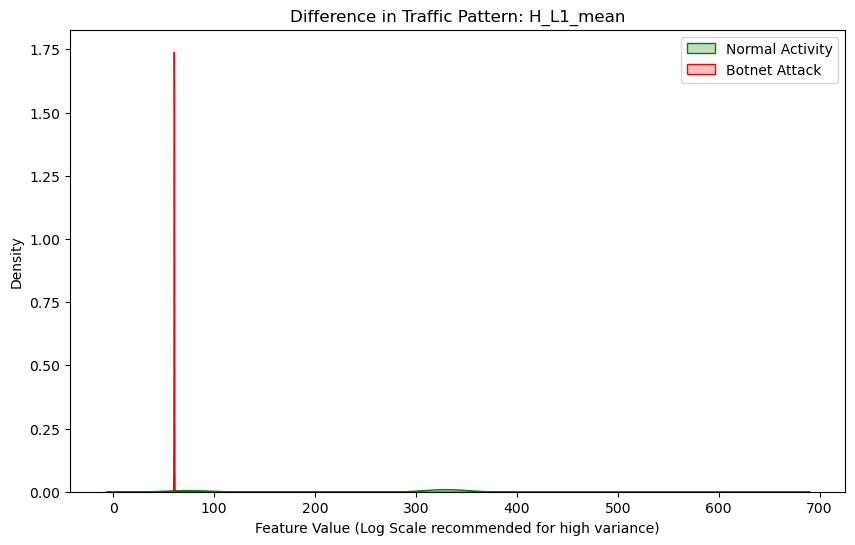

--- Testing 5 Random Samples ---
Sample 1: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 2: AI Predicted BOTNET | Actual was BOTNET -> SUCCESS
Sample 3: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 4: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS
Sample 5: AI Predicted NORMAL | Actual was NORMAL -> SUCCESS


In [9]:
# Step 1: Environment Setup & Library Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# This line checks if your data folder is connected correctly
print("Files found in data folder:", os.listdir('data2'))
device_name = 'SimpleHome_XCS7_1003_WHT_Security_Camera'


# Step 2: Data Loading and Sampling

# Load the files from your 'data' folder
df_benign = pd.read_csv(f'data2/{device_name}/benign_traffic.csv').head(5000)
df_attack = pd.read_csv(f'data2/{device_name}/udpplain.csv').head(5000)

print(f"Successfully loaded {len(df_benign)} benign rows and {len(df_attack)} attack rows.")
print(f"Now analyzing: {device_name}")

pd.set_option('display.max_columns', None)
df_benign.head()

# Step 3: Data Labeling, Merging, and Shuffling

# Create the labels
df_benign['is_botnet'] = 0
df_attack['is_botnet'] = 1

# Merge both into one single table
df_combined = pd.concat([df_benign, df_attack], axis=0).reset_index(drop=True)

# Shuffle the data so the AI doesn't see all zeros then all ones
df_combined = df_combined.sample(frac=1).reset_index(drop=True)

print("Dataset is merged and labeled. Total rows:", len(df_combined))

# Step 4: Class Distribution Visualization

plt.figure(figsize=(6,4))
sns.countplot(x='is_botnet', data=df_combined, hue='is_botnet', palette='viridis') 
plt.title('Distribution: Normal (0) vs. Botnet (1)')
plt.xticks([0, 1], ['Benign (0)', 'Botnet (1)'])
plt.show()

# Step 5: Feature Selection & Data Splitting

# Select features (all columns except the label) and the target label
X = df_combined.drop('is_botnet', axis=1)
y = df_combined['is_botnet']

# Split: 70% for training, 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=42)

print(f"Data split complete.")
print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")

# Step 6: Model Initialization and Training

# Initialize the Random Forest
model = RandomForestClassifier(n_estimators=10, max_depth=2, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("AI Model Training Complete!")

# Step 7: Model Evaluation & Visual Proof
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

#Predict on the test data
y_pred = model.predict(X_test)

#Calculate the accuracy score and store it in a variable
current_accuracy = accuracy_score(y_test, y_pred)

#Print accuracy report
print("Classification Report:")
print(classification_report(y_test, y_pred))

#Display visual proof
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')

print(f"Accuracy Score: {current_accuracy:.4f}")

plt.title("Botnet Detection Accuracy Results")
plt.show()
# Step 8: Model Deployment & Persistence

import joblib
joblib.dump(model, 'botnet_detector.pkl')
print("Model saved successfully as 'botnet_detector.pkl'")

# Step 9: Model Loading & Real-Time Inference Simulation

# Load the model back to prove it was saved correctly
loaded_model = joblib.dump(model, 'botnet_detector.pkl') # Use joblib.load if restarting
test_sample = X_test.iloc[0:1] # Take one row of network traffic
prediction = model.predict(test_sample)

if prediction[0] == 1:
    print("ALERT: Botnet Activity Detected!")
else:
    print("STATUS: Network Traffic is Normal.")

# Step 10: Feature Importance (The "Red Flags")

importances = model.feature_importances_
feature_names = X.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot the top 10 features
feat_imp.head(10).plot(kind='barh', color='orange')
plt.title("Top 10 Indicators of Botnet Behavior")
plt.show()

# Step 11: Density Distribution Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# We select the most important feature found 
feature_to_plot = 'H_L1_mean'

plt.figure(figsize=(10, 6))

# Plotting the distribution for Benign traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 0][feature_to_plot], 
            label='Normal Activity', fill=True, color='green')

# Plotting the distribution for Botnet traffic
sns.kdeplot(df_combined[df_combined['is_botnet'] == 1][feature_to_plot], 
            label='Botnet Attack', fill=True, color='red')

plt.title(f'Difference in Traffic Pattern: {feature_to_plot}')
plt.xlabel('Feature Value (Log Scale recommended for high variance)')
plt.ylabel('Density')
plt.legend()
plt.show()

# Step 12: Randomized Verification

# Pick 5 random rows
random_samples = X_test.sample(5)

# Predict for all 5
predictions = model.predict(random_samples)

# Get the actual labels for all 5
actual_labels = y_test.loc[random_samples.index].values

print(f"--- Testing 5 Random Samples ---")

# Loop through each sample to show the result
for i in range(5):
    status = "SUCCESS" if predictions[i] == actual_labels[i] else "FAILURE"
    pred_text = "BOTNET" if predictions[i] == 1 else "NORMAL"
    true_text = "BOTNET" if actual_labels[i] == 1 else "NORMAL"

    print(f"Sample {i+1}: AI Predicted {pred_text} | Actual was {true_text} -> {status}")


In [15]:
import pandas as pd

results_data = [
    {
        "Device Name": "Danmini Doorbell", 
        "Botnet Type": "gafgyt", 
        "Accuracy (%)": 99.89, 
        "Top Feature": "H_L0.01_weight, H_L1_mean, M1_dir_L1_mean, H_L0.01_mean, H_L5_mean"
    },
    {
        "Device Name": "Ecobee Thermostat", 
        "Botnet Type": "gafgyt", 
        "Accuracy (%)": 99.84,
        "Top Feature": "H_L0.01_mean"
    },
	
	{
   	"Device Name": "Ennio doorbell", 
        "Botnet Type": "gafgyt", 
        "Accuracy (%)": 99.87,
        "Top Feature": "H_L0.01_weight, H_L1_mean, M1_dir_L1_mean, H_L0.01_mean, H_L5_mean"
    },
    {
        "Device Name": "Philips Baby Monitor", 
        "Botnet Type": "gafgyt", 
        "Accuracy (%)": 99.80, 
        "Top Feature": "H_L0.01_weight,M1_dir_L1_mean"
    },
    {
        "Device Name": "Provision Security Camera 737E", 
        "Botnet Type": "gafgyt", 
        "Accuracy (%)": 99.89,
        "Top Feature": "H_L0.01_mean"
    },
    {
        "Device Name": "Provision Security Camera 838", 
        "Botnet Type": "gafgyt", 
        "Accuracy (%)": 99.88, 
        "Top Feature": "H_L0.01_weight,H_L0.01_mean"
    },
	{
	"Device Name": "Samsung SNH 1011 webcam", 
        "Botnet Type": "gafgyt", 
        "Accuracy (%)": 99.98,
        "Top Feature": "H_L0.01_weight, H_L1_mean"
    },
    {
        "Device Name": "SimpleHome Security Camera 1002", 
        "Botnet Type": "gafgyt", 
        "Accuracy (%)": 99.87, 
        "Top Feature": "H_L0.01_weight, H_L1_mean, M1_dir_L1_mean, H_L0.01_mean, H_L5_mean"
    },
    {
        "Device Name": "SimpleHome Security Camera 1003", 
        "Botnet Type": "gafgyt", 
        "Accuracy (%)": 99.89, 
        "Top Feature": "H_L0.01_weight,H_L0.01_mean"
    }
]

# DataFrame
df_results = pd.DataFrame(results_data)

# 3.Formatting 
print("--- TABLE : MULTI-DEVICE BOTNET DETECTION PERFORMANCE( BASHLITE ) ---")
formatted_table = df_results.style.format({
    "Accuracy (%)": "{:.2f}"
}).hide(axis='index')

# Display the table
display(formatted_table)

--- TABLE : MULTI-DEVICE BOTNET DETECTION PERFORMANCE( BASHLITE ) ---


Device Name,Botnet Type,Accuracy (%),Top Feature
Danmini Doorbell,gafgyt,99.89,"H_L0.01_weight, H_L1_mean, M1_dir_L1_mean, H_L0.01_mean, H_L5_mean"
Ecobee Thermostat,gafgyt,99.84,H_L0.01_mean
Ennio doorbell,gafgyt,99.87,"H_L0.01_weight, H_L1_mean, M1_dir_L1_mean, H_L0.01_mean, H_L5_mean"
Philips Baby Monitor,gafgyt,99.80,"H_L0.01_weight,M1_dir_L1_mean"
Provision Security Camera 737E,gafgyt,99.89,H_L0.01_mean
Provision Security Camera 838,gafgyt,99.88,"H_L0.01_weight,H_L0.01_mean"
Samsung SNH 1011 webcam,gafgyt,99.98,"H_L0.01_weight, H_L1_mean"
SimpleHome Security Camera 1002,gafgyt,99.87,"H_L0.01_weight, H_L1_mean, M1_dir_L1_mean, H_L0.01_mean, H_L5_mean"
SimpleHome Security Camera 1003,gafgyt,99.89,"H_L0.01_weight,H_L0.01_mean"


In [16]:
# Cross-Malware Test Analysis
import joblib
from sklearn.metrics import accuracy_score

# 1. Load the model you saved from the Mirai notebook
loaded_model = joblib.load('botnet_detector.pkl')

# 2. Test on the Bashlite data (X_test from this notebook)
y_transfer_pred = loaded_model.predict(X_test)

# 3. Get the score
transfer_acc = accuracy_score(y_test, y_transfer_pred)
print(f"Test Result - Cross-Malware Accuracy: {transfer_acc*100:.2f}%")

Test Result - Cross-Malware Accuracy: 49.83%


In [13]:
import joblib
# Use the variable name of your Bashlite model (e.g., 'model' or 'bashlite_rf')
joblib.dump(model, 'bashlite_detector.pkl')
print("Bashlite model saved successfully!")

Bashlite model saved successfully!


In [14]:
# Performance Metrics
import time

# Select 1000 random samples to get a very accurate average
samples = X_test.sample(1000)

start_time = time.perf_counter()
model.predict(samples) # Predict 1000 packets at once
end_time = time.perf_counter()

# Calculate time per single packet in milliseconds
total_time_ms = (end_time - start_time) * 1000
latency_per_packet = total_time_ms / 1000

print(f"--- PERFORMANCE METRICS ---")
print(f"Total time for 1000 packets: {total_time_ms:.4f} ms")
print(f"Inference Latency per packet: {latency_per_packet:.6f} ms")

--- PERFORMANCE METRICS ---
Total time for 1000 packets: 5.5669 ms
Inference Latency per packet: 0.005567 ms
